In [1]:
import json
from collections import defaultdict
from emb_diversity import measure_diversity
from scipy.stats import spearmanr

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate scores

In [2]:
# Load texts
with open("correlation_texts_100lines_final.json", "r") as f:
    data = json.load(f)

In [3]:
# Print number of domains
print(len(data))

17


In [4]:
# Print domains
for domain, lines in data.items():
    print(domain)

common-pile/arxiv_abstracts_filtered
common-pile/youtube_filtered
common-pile/news_filtered
common-pile/regulations_filtered
common-pile/foodista_filtered
common-pile/github_archive_filtered
common-pile/wikiteam_filtered
common-pile/wikimedia_filtered
common-pile/usgpo_filtered
common-pile/ubuntu_irc_filtered
common-pile/stackv2_edu_filtered
common-pile/stackexchange_filtered
common-pile/pubmed_filtered
common-pile/data_provenance_initiative_filtered
common-pile/cccc_filtered
common-pile/biodiversity_heritage_library_filtered
common-pile/stackv2_html_filtered


In [5]:
# Define all measures to test
measures = ['bins_entropy', 'bottleneck', 'chamfer_dist', 'cluster_inertia', 'convex_hull_volume_3d', 'dcscore', 'diameter', 'energy', 'geo_mean_std', 'graph_entropy', 'hamdiv', 'knn', 'log_determinant', 'mean_pw_dist', 'mst_dispersion', 'renyi_entropy', 'span_centroid', 'span_medoid', 'sum_bottleneck', 'sum_diameter', 'sum_pairwise_dist', 'vendi_score']

In [ ]:
scores = defaultdict(list)

for measure in measures:
    print("Working on:", measure)
    for domain, lines in data.items():
        scores[measure].append(measure_diversity(lines, measure=[measure])[measure]["value"])

scores

In [7]:
# Convert dict to DataFrame (columns = metrics, rows = datasets)
df = pd.DataFrame(scores)
df.to_json("scores_per_measure.json", indent=2)

In [8]:
df

,bins_entropy,bottleneck,chamfer_dist,cluster_inertia,convex_hull_volume_3d,dcscore,diameter,energy,geo_mean_std,graph_entropy,...,log_determinant,mean_pw_dist,mst_dispersion,renyi_entropy,span_centroid,span_medoid,sum_bottleneck,sum_diameter,sum_pairwise_dist,vendi_score
0,0.867234,0.339630,0.521454,0.339630,13.984749,2.299003,1.153391,-1.200273,0.029441,458.648780,...,-59.194821,0.851123,53.849477,3.103107,0.723690,0.773642,52.145394,105.498235,4213.056455,48.904212
1,0.927173,0.542637,0.680504,0.553618,12.048389,2.513526,1.173141,-1.074023,0.030322,459.115217,...,-34.382561,0.940042,69.367713,3.854920,0.898807,0.874105,68.050385,110.333633,4653.208803,69.713875
2,0.929353,0.125623,0.490726,0.125623,13.032071,2.296419,1.133301,-1.210724,0.028717,458.585230,...,-61.916776,0.849563,51.658270,3.064886,0.742799,0.720703,49.072645,105.846040,4205.336371,48.465533
3,0.432797,0.000523,0.255827,0.000523,75.752897,1.981900,1.075587,-5.146614,0.025912,454.474909,...,-209.670422,0.706849,28.985713,2.004311,0.683292,0.577377,25.582684,99.555020,3498.902947,20.378964
4,0.932349,0.330330,0.536069,0.330330,13.850784,2.265885,1.123541,-1.218362,0.028133,458.823923,...,-58.997361,0.834972,54.687268,3.057341,0.670545,0.728249,53.606865,102.396812,4133.113870,48.975162
5,0.836949,0.011827,0.515678,0.011827,17.211219,2.312670,1.148347,-1.672545,0.029111,456.279514,...,-95.147225,0.862694,53.152064,2.786888,0.829172,0.712366,51.567820,108.447371,4270.334156,41.030332
6,0.864714,0.000198,0.503693,0.000198,18.437822,2.362289,1.136955,-3.119013,0.029135,458.546607,...,-74.659983,0.879049,54.029824,3.266452,0.802709,0.802338,50.369267,107.122740,4351.294298,51.652203
7,0.858501,0.000714,0.427041,0.000714,15.608656,2.382931,1.175935,-1.854650,0.029702,458.308446,...,-80.216917,0.889957,47.747975,3.231273,0.818071,0.800018,42.704089,107.046397,4405.288228,48.773758
8,0.565039,0.000184,0.029510,0.000184,2141.515895,1.401028,0.617882,-37.934933,0.017299,449.800263,...,-479.489239,0.349491,5.583852,0.803738,0.223345,0.288260,2.951026,53.606196,1729.980158,4.547570
9,0.935600,0.222519,0.507322,0.222519,11.884329,2.200818,1.142316,-1.288858,0.028182,458.325196,...,-62.901727,0.804786,51.623691,2.706494,0.795115,0.664735,50.732189,104.609467,3983.689758,43.261122


In [9]:
corr = df.corr(method="spearman")
corr.to_json("measures_correlated.json", indent=2)

In [10]:
corr

,bins_entropy,bottleneck,chamfer_dist,cluster_inertia,convex_hull_volume_3d,dcscore,diameter,energy,geo_mean_std,graph_entropy,...,log_determinant,mean_pw_dist,mst_dispersion,renyi_entropy,span_centroid,span_medoid,sum_bottleneck,sum_diameter,sum_pairwise_dist,vendi_score
bins_entropy,1.000000,0.448529,0.448529,0.448529,-0.860294,0.372549,0.321078,0.541667,0.362745,0.752451,...,0.568627,0.333333,0.500000,0.446078,0.267157,0.365196,0.448529,0.188725,0.333333,0.561275
bottleneck,0.448529,1.000000,0.862745,1.000000,-0.651961,0.480392,0.252451,0.848039,0.571078,0.742647,...,0.835784,0.485294,0.730392,0.551471,0.345588,0.514706,0.862745,0.294118,0.485294,0.659314
chamfer_dist,0.448529,0.862745,1.000000,0.862745,-0.480392,0.781863,0.335784,0.882353,0.799020,0.823529,...,0.941176,0.776961,0.946078,0.803922,0.654412,0.762255,1.000000,0.529412,0.776961,0.867647
cluster_inertia,0.448529,1.000000,0.862745,1.000000,-0.651961,0.480392,0.252451,0.848039,0.571078,0.742647,...,0.835784,0.485294,0.730392,0.551471,0.345588,0.514706,0.862745,0.294118,0.485294,0.659314
convex_hull_volume_3d,-0.860294,-0.651961,-0.480392,-0.651961,1.000000,-0.232843,-0.433824,-0.602941,-0.289216,-0.669118,...,-0.563725,-0.203431,-0.416667,-0.316176,-0.196078,-0.220588,-0.480392,-0.227941,-0.203431,-0.438725
dcscore,0.372549,0.480392,0.781863,0.480392,-0.232843,1.000000,0.490196,0.767157,0.975490,0.762255,...,0.813725,0.997549,0.865196,0.975490,0.887255,0.960784,0.781863,0.669118,0.997549,0.911765
diameter,0.321078,0.252451,0.335784,0.252451,-0.433824,0.490196,1.000000,0.421569,0.556373,0.375000,...,0.338235,0.473039,0.325980,0.446078,0.473039,0.411765,0.335784,0.735294,0.473039,0.399510
energy,0.541667,0.848039,0.882353,0.848039,-0.602941,0.767157,0.421569,1.000000,0.823529,0.860294,...,0.946078,0.762255,0.848039,0.803922,0.639706,0.737745,0.882353,0.534314,0.762255,0.830882
geo_mean_std,0.362745,0.571078,0.799020,0.571078,-0.289216,0.975490,0.556373,0.823529,1.000000,0.772059,...,0.838235,0.977941,0.845588,0.965686,0.848039,0.953431,0.799020,0.666667,0.977941,0.899510
graph_entropy,0.752451,0.742647,0.823529,0.742647,-0.669118,0.762255,0.375000,0.860294,0.772059,1.000000,...,0.924020,0.747549,0.877451,0.852941,0.544118,0.808824,0.823529,0.443627,0.747549,0.936275


# Calculate Correlation

In [11]:
def pairwise_correlations(results_dict):
    metrics = list(results_dict.keys())
    out = {}

    for i in range(len(metrics)):
        for j in range(i+1, len(metrics)):
            m1, m2 = metrics[i], metrics[j]
            corr, pval = spearmanr(results_dict[m1], results_dict[m2])
            out[(m1, m2)] = (corr, pval)

    return out

# Plot correlation heatmap (options)

In [12]:
pairwise_correlations(scores)

{('bins_entropy', 'bottleneck'): (np.float64(0.44852941176470595),
  np.float64(0.07094643963763714)),
 ('bins_entropy', 'chamfer_dist'): (np.float64(0.44852941176470595),
  np.float64(0.07094643963763714)),
 ('bins_entropy', 'cluster_inertia'): (np.float64(0.44852941176470595),
  np.float64(0.07094643963763714)),
 ('bins_entropy', 'convex_hull_volume_3d'): (np.float64(-0.8602941176470589),
  np.float64(9.427383759906555e-06)),
 ('bins_entropy', 'dcscore'): (np.float64(0.37254901960784315),
  np.float64(0.14083572189262192)),
 ('bins_entropy', 'diameter'): (np.float64(0.32107843137254904),
  np.float64(0.208898183250939)),
 ('bins_entropy', 'energy'): (np.float64(0.5416666666666667),
  np.float64(0.02471480173457982)),
 ('bins_entropy', 'geo_mean_std'): (np.float64(0.36274509803921573),
  np.float64(0.15242989215413413)),
 ('bins_entropy', 'graph_entropy'): (np.float64(0.752450980392157),
  np.float64(0.0004921108243565306)),
 ('bins_entropy', 'hamdiv'): (np.float64(0.5955882352941178)

In [13]:
def plot_metric_correlation_heatmap(results_dict, method="spearman"):
    """
    results_dict: {metric_name: [values across datasets]}
    method: 'pearson', 'spearman', or 'kendall'
    """

    # Convert dict → DataFrame (columns = metrics, rows = datasets)
    df = pd.DataFrame(results_dict)

    # Compute correlation matrix
    corr = df.corr(method=method)

    # Plot heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8}
    )

    plt.title(f"{method.capitalize()} Correlation Among Metrics", fontsize=14)
    plt.tight_layout

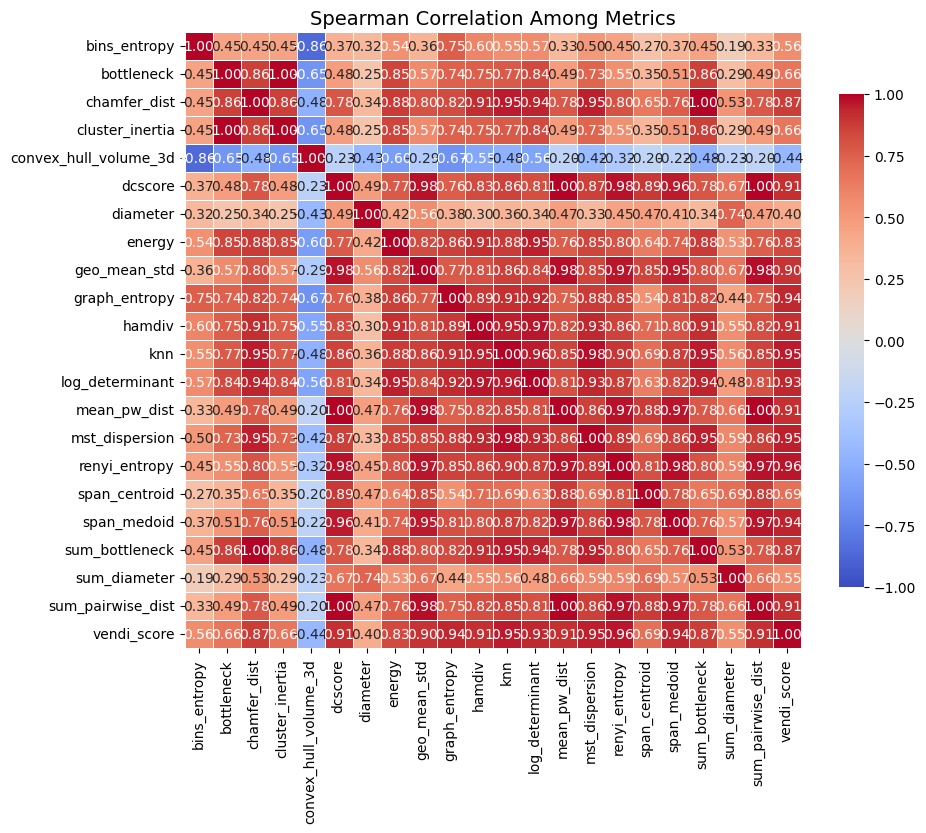

In [14]:
corr = plot_metric_correlation_heatmap(scores)